In [ ]:

# SESSAO 03 - TAREFA 01
# Identificacao das classes do Dataset 3W

import requests
import configparser
import pandas as pd

# Endereco do arquivo oficial de configuracao
url = (
    "https://raw.githubusercontent.com/"
    "petrobras/3W/main/dataset/dataset.ini"
)

# Acessar o arquivo
resposta = requests.get(url, timeout=30)
resposta.raise_for_status()

# Ler as configuracoes do dataset
config = configparser.ConfigParser(
    interpolation=None
)

config.read_string(resposta.text)

# Verificar a versao
versao = config["VERSION"]["DATASET"]

print("Versao do Dataset:", versao)

# Obter os nomes das categorias
nomes = config["EVENTS"]["NAMES"].split(",")

# Criar uma lista para guardar os resultados
categorias = []

for nome in nomes:

    nome = nome.strip()

    codigo = config[nome]["LABEL"]
    descricao = config[nome]["DESCRIPTION"]

    categorias.append({
        "Codigo": int(codigo),
        "Nome": nome,
        "Descricao": descricao
    })

# Transformar em tabela
tabela_categorias = pd.DataFrame(categorias)

# Organizar pela numeracao das classes
tabela_categorias = tabela_categorias.sort_values(
    by="Codigo"
)

# Mostrar a tabela
display(tabela_categorias)

Versao do Dataset: 2.0.0


,Codigo,Nome,Descricao
0,0,NORMAL,Normal Operation
1,1,ABRUPT_INCREASE_OF_BSW,Abrupt Increase of BSW
2,2,SPURIOUS_CLOSURE_OF_DHSV,Spurious Closure of DHSV
3,3,SEVERE_SLUGGING,Severe Slugging
4,4,FLOW_INSTABILITY,Flow Instability
5,5,RAPID_PRODUCTIVITY_LOSS,Rapid Productivity Loss
6,6,QUICK_RESTRICTION_IN_PCK,Quick Restriction in PCK
7,7,SCALING_IN_PCK,Scaling in PCK
8,8,HYDRATE_IN_PRODUCTION_LINE,Hydrate in Production Line
9,9,HYDRATE_IN_SERVICE_LINE,Hydrate in Service Line


In [ ]:

# SESSAO 03 - TAREFA 02
# Contagem de arquivos por categoria

contagem = []

for codigo in range(10):

    url_api = (
        "https://api.github.com/repos/"
        f"petrobras/3W/contents/dataset/{codigo}"
    )

    resposta = requests.get(
        url_api,
        timeout=30
    )

    resposta.raise_for_status()

    arquivos = resposta.json()

    arquivos_parquet = [
        arquivo for arquivo in arquivos
        if arquivo["type"] == "file"
        and arquivo["name"].endswith(".parquet")
    ]

    quantidade = len(arquivos_parquet)

    contagem.append({
        "Codigo": codigo,
        "Quantidade_arquivos": quantidade
    })

    print(
        f"Categoria {codigo}: "
        f"{quantidade} arquivos"
    )

# Criar tabela com os resultados
tabela_contagem = pd.DataFrame(contagem)

# Adicionar nomes das categorias
tabela_contagem = tabela_contagem.merge(
    tabela_categorias[["Codigo", "Nome"]],
    on="Codigo",
    how="left"
)

# Calcular porcentagem por categoria
total = tabela_contagem["Quantidade_arquivos"].sum()

tabela_contagem["Percentual"] = (
    tabela_contagem["Quantidade_arquivos"]
    / total * 100
)

print("\nTotal de arquivos:", total)

display(tabela_contagem.round(2))

# Avisar caso a API atinja seu limite de listagem
if tabela_contagem["Quantidade_arquivos"].max() >= 1000:
    print(
        "ATENCAO: conferir a contagem. "
        "A API pode limitar listagens extensas."
    )


Categoria 0: 594 arquivos
Categoria 1: 128 arquivos
Categoria 2: 38 arquivos
Categoria 3: 106 arquivos
Categoria 4: 343 arquivos
Categoria 5: 450 arquivos
Categoria 6: 221 arquivos
Categoria 7: 46 arquivos
Categoria 8: 95 arquivos
Categoria 9: 207 arquivos

Total de arquivos: 2228


,Codigo,Quantidade_arquivos,Nome,Percentual
0,0,594,NORMAL,26.66
1,1,128,ABRUPT_INCREASE_OF_BSW,5.75
2,2,38,SPURIOUS_CLOSURE_OF_DHSV,1.71
3,3,106,SEVERE_SLUGGING,4.76
4,4,343,FLOW_INSTABILITY,15.39
5,5,450,RAPID_PRODUCTIVITY_LOSS,20.20
6,6,221,QUICK_RESTRICTION_IN_PCK,9.92
7,7,46,SCALING_IN_PCK,2.06
8,8,95,HYDRATE_IN_PRODUCTION_LINE,4.26
9,9,207,HYDRATE_IN_SERVICE_LINE,9.29


In [ ]:

# SESSAO 03 - TAREFA 03
# Identificacao da origem das instancias

url_arvore = (
    "https://api.github.com/repos/"
    "petrobras/3W/git/trees/main?recursive=1"
)

resposta = requests.get(
    url_arvore,
    timeout=60
)

resposta.raise_for_status()

dados_arvore = resposta.json()

if dados_arvore.get("truncated", False):
    raise ValueError(
        "A listagem foi truncada. "
        "Nao podemos usar uma contagem incompleta."
    )

registros = []

for item in dados_arvore["tree"]:

    caminho = item["path"]
    partes = caminho.split("/")

    # Selecionar somente os arquivos das classes 0 a 9
    if len(partes) != 3:
        continue

    if partes[0] != "dataset":
        continue

    if partes[1] not in [str(i) for i in range(10)]:
        continue

    nome = partes[2]

    if not nome.endswith(".parquet"):
        continue

    # Identificar a origem
    if nome.startswith("WELL-"):
        origem = "Real"
        poco = nome.split("_")[0]

    elif nome.startswith("SIMULATED_"):
        origem = "Simulada"
        poco = None

    elif nome.startswith("DRAWN_"):
        origem = "Especialista"
        poco = None

    else:
        origem = "Nao identificada"
        poco = None

    registros.append({
        "Categoria": int(partes[1]),
        "Arquivo": nome,
        "Origem": origem,
        "Poco": poco
    })

# Criar a tabela
inventario = pd.DataFrame(registros)

# Contar arquivos por origem
resumo_origens = (
    inventario["Origem"]
    .value_counts()
    .rename_axis("Origem")
    .reset_index(name="Quantidade")
)

print("Distribuicao por origem:")
display(resumo_origens)

print("\nTotal de arquivos:", len(inventario))

# Identificar os pocos reais distintos
quantidade_pocos = (
    inventario["Poco"].dropna().nunique()
)

print("Pocos reais distintos:", quantidade_pocos)

# Mostrar exemplos de nomes de arquivos
print("\nExemplos de arquivos por origem:")

for origem in inventario["Origem"].unique():
    exemplo = inventario[
        inventario["Origem"] == origem
    ]["Arquivo"].iloc[0]

    print(origem, ":", exemplo)


Distribuicao por origem:


,Origem,Quantidade
0,Real,1119
1,Simulada,1089
2,Especialista,20



Total de arquivos: 2228
Pocos reais distintos: 40

Exemplos de arquivos por origem:
Real : WELL-00001_20170201010207.parquet
Especialista : DRAWN_00001.parquet
Simulada : SIMULATED_00001.parquet


In [ ]:

# SESSAO 03 - TAREFA 04
# Leitura de um evento indesejado - Classe 2

import io

# Selecionar arquivos reais da categoria 2
arquivos_classe2 = inventario[
    (inventario["Categoria"] == 2) &
    (inventario["Origem"] == "Real")
]

print(
    "Arquivos reais da classe 2:",
    len(arquivos_classe2)
)

# Escolher o primeiro arquivo da lista
nome_evento = arquivos_classe2.iloc[0]["Arquivo"]

print("Arquivo selecionado:", nome_evento)

# Montar o endereco do arquivo
url_evento = (
    "https://raw.githubusercontent.com/"
    "petrobras/3W/main/dataset/2/"
    + nome_evento
)

# Baixar o arquivo
resposta = requests.get(
    url_evento,
    timeout=120
)

resposta.raise_for_status()

# Ler os dados
df_evento = pd.read_parquet(
    io.BytesIO(resposta.content)
)

# Examinar a estrutura
print("\nDimensoes:")
print(df_evento.shape)

print("\nPeriodo da serie:")
print("Inicio:", df_evento.index.min())
print("Fim:", df_evento.index.max())

# Verificar a classificacao
print("\nDistribuicao da coluna class:")
print(
    df_evento["class"].value_counts(
        dropna=False
    )
)

# Verificar a disponibilidade dos sensores
print("\nVariaveis com dados disponiveis:")

variaveis = df_evento.notna().sum()

display(
    variaveis[
        variaveis > 0
    ].sort_values(ascending=False)
)

# Visualizar os primeiros registros
display(df_evento.head())


Arquivos reais da classe 2: 22
Arquivo selecionado: WELL-00002_20131104004101.parquet

Dimensoes:
(12721, 29)

Periodo da serie:
Inicio: 2013-11-04 00:41:01
Fim: 2013-11-04 04:13:01

Distribuicao da coluna class:
class
102     5149
0       3755
<NA>    3600
2        217
Name: count, dtype: Int64

Variaveis com dados disponiveis:


,0
P-ANULAR,12721
P-PDG,12721
P-TPT,12721
T-TPT,12721
class,9121
state,9121


,ABER-CKGL,ABER-CKP,ESTADO-DHSV,ESTADO-M1,ESTADO-M2,ESTADO-PXO,ESTADO-SDV-GL,ESTADO-SDV-P,ESTADO-W1,ESTADO-W2,...,PT-P,P-TPT,QBS,QGL,T-JUS-CKP,T-MON-CKP,T-PDG,T-TPT,class,state
timestamp,,,,,,,,,,,,,,,,,,,,,
2013-11-04 00:41:01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,18814780.0,NaN,NaN,NaN,NaN,NaN,116.7727,<NA>,<NA>
2013-11-04 00:41:02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,18815110.0,NaN,NaN,NaN,NaN,NaN,116.7724,<NA>,<NA>
2013-11-04 00:41:03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,18815440.0,NaN,NaN,NaN,NaN,NaN,116.7722,<NA>,<NA>
2013-11-04 00:41:04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,18815770.0,NaN,NaN,NaN,NaN,NaN,116.7720,<NA>,<NA>
2013-11-04 00:41:05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,18816110.0,NaN,NaN,NaN,NaN,NaN,116.7718,<NA>,<NA>


Valores diferentes por sensor:
P-ANULAR : 4903
P-PDG : 1
P-TPT : 5888
T-TPT : 7039


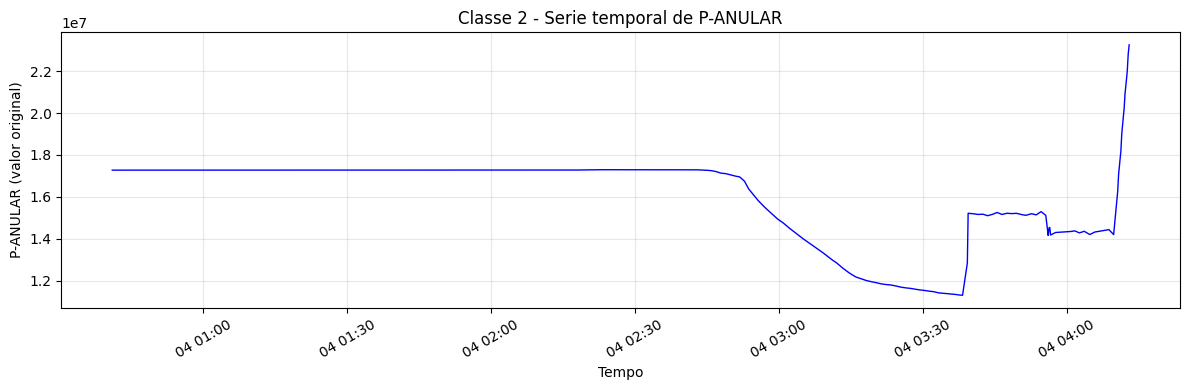

P-PDG - sensor constante nesta instancia


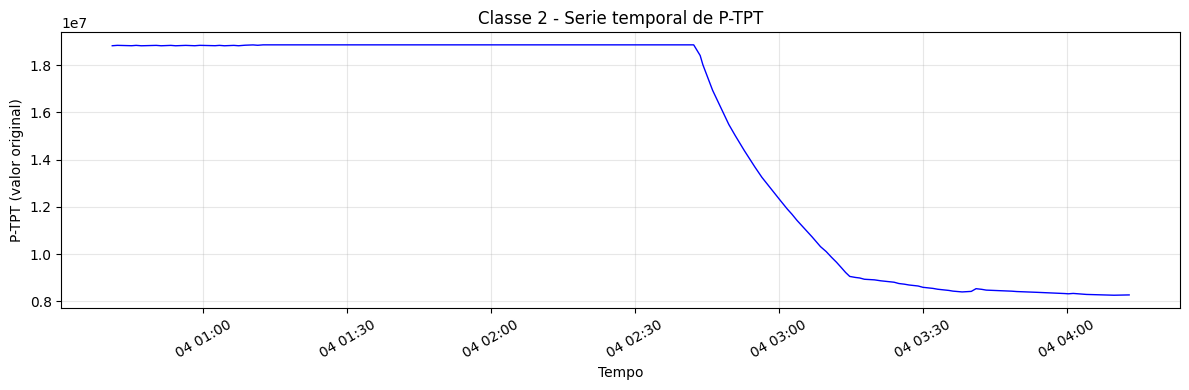

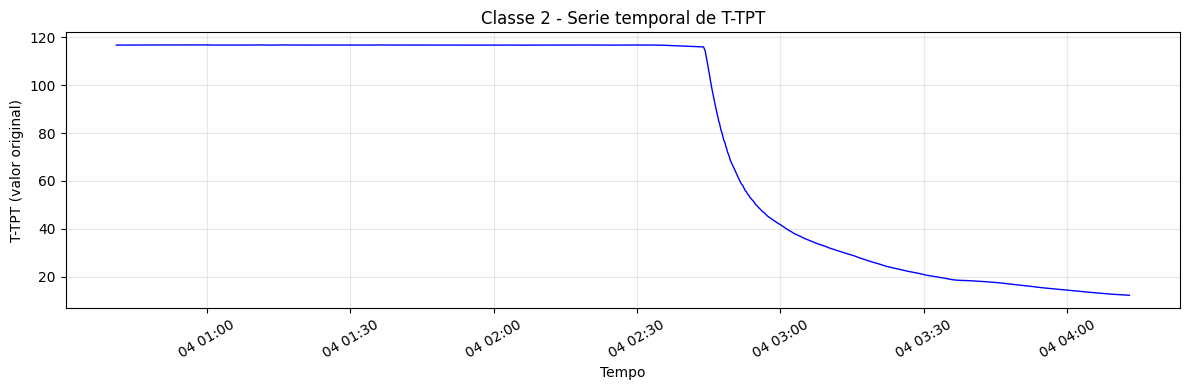

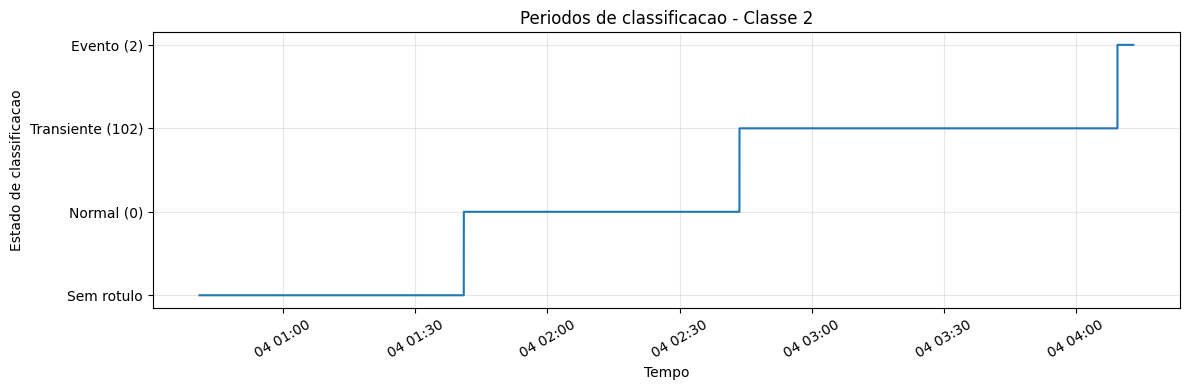

In [ ]:

# SESSAO 03 - TAREFA 05
# Analise temporal de um evento da classe 2

import matplotlib.pyplot as plt

# 1. Identificar os sensores com variacao
sensores_evento = [
    "P-ANULAR",
    "P-PDG",
    "P-TPT",
    "T-TPT"
]

print("Valores diferentes por sensor:")

for sensor in sensores_evento:
    print(
        sensor,
        ":",
        df_evento[sensor].nunique()
    )

# 2. Criar graficos dos sensores
# que apresentam variacao

for sensor in sensores_evento:

    if df_evento[sensor].nunique() <= 1:
        print(
            sensor,
            "- sensor constante nesta instancia"
        )
        continue

    plt.figure(figsize=(12, 4))

    plt.plot(
        df_evento.index,
        df_evento[sensor],
        color="blue",
        linewidth=1
    )

    plt.title(
        f"Classe 2 - Serie temporal de {sensor}"
    )

    plt.xlabel("Tempo")
    plt.ylabel(f"{sensor} (valor original)")

    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# 3. Mostrar os periodos de classificacao

# Converter os rotulos em niveis
# para facilitar a visualizacao
mapa_rotulos = {
    0: 0,
    102: 1,
    2: 2
}

rotulos = (
    df_evento["class"]
    .map(mapa_rotulos)
    .fillna(-1)
)

plt.figure(figsize=(12, 4))

plt.step(
    df_evento.index,
    rotulos,
    where="post",
    linewidth=1.5
)

plt.yticks(
    [-1, 0, 1, 2],
    [
        "Sem rotulo",
        "Normal (0)",
        "Transiente (102)",
        "Evento (2)"
    ]
)

plt.title("Periodos de classificacao - Classe 2")
plt.xlabel("Tempo")
plt.ylabel("Estado de classificacao")

plt.grid(True, alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
